# ChillBot — AI chatbot o chilli papričkách


| Část | Komponenta | Co dělá |
|---|---|---|
| **A** | **Model predikce produkce** | Z dat FAOSTAT předpovídá, zda produkce paprik v dané zemi **vzroste** oproti minulému roku. |
| **B** | **Obrazový model** | Doladěný ResNet18, který z fotografie rozpozná **13 odrůd chilli**. |
| **C** | **Nástroje pro LLM** | Oba modely jsou zpřístupněny jako tools (nástroje) (`predict_production_rise`, `classify_plant_type`), které LLM volá přes function calling. |
| **D** | **Chatbot** | LLM přes endpoint kompatibilní s OpenAI, který volá nástroje z části C a odpovídá s pomocí **RAG** nad znalostní bází z PDF (ChromaDB).|


In [1]:
# Balíčky navíc ke standardní sadě (numpy, pandas, matplotlib, scikit-learn).
# Instalace všech najednou z kořene repozitáře:  pip install -e .
# nebo jednotlivě:
# %pip install joblib                      
# %pip install torch torchvision Pillow    
# %pip install huggingface-hub             
# %pip install chromadb==1.5.9             
# %pip install langchain-text-splitters==1.1.3  
# %pip install pypdf==6.20.0               
# %pip install openai==3.28.0             

# Část A — Model predikce produkce

## A.1 Data

**Úloha:** pro danou zemi, typ papriky (čerstvé / sušené) a rok předpovědět, zda **produkce vzroste oproti předchozímu roku** (`production_rise` = 1), nebo ne (0). Jde o binární klasifikaci.

**Zdroj:** [FAOSTAT](https://www.fao.org/faostat/en/#data/QCL) (FAO), doména QCL (plodiny), roční data za 1961–2024 podle zemí:
- `papriky-fresh.csv`: *Chillies and peppers, green* (čerstvé papriky, statisticky zelenina)
- `papriky-dry.csv`: *Chillies and peppers, dry* (sušené, nezpracované; statisticky koření)
- `temperatureChange.csv`: změna teploty podle FAOSTAT pro každou zemi a rok (+ směrodatná odchylka)
- `pricePeppers.csv`: ceny výrobců podle FAOSTAT

## A.2 Příprava dat

Kód níže (v repozitáři třída `DataPrep`, zde přepsaný na obyčejný sekvenční kód) sestavuje výsledný modelovací dataset `papriky-production.csv`. Rozhodnutí, která v něm padla:

1. **Odstraněné sloupce.** `Domain Code`, `Domain`, `Element Code`, `Item Code (CPC)`, `Year Code` a `Note` jsou konstantní nebo duplikují jiné sloupce.
2. **Odstraněné země**, které již neexistují (SSSR, SFR Jugoslávie, Československo, …), aby se jejich časové řady nepřekrývaly s nástupnickými státy. Odstraněna je i **Čína**, protože ji FAOSTAT uvádí jak jako celek, tak rozdělenou na pevninskou Čínu, Tchaj-wan atd.
3. Sloupce přejmenovány do snake_case. Data pro čerstvé a sušené papriky jsou **spojena** a **pivotována** tak, aby se z `production`, `area_harvested` a `yield` staly sloupce.
4. **Chybějící hodnoty.** Pokud chybí jen jeden ze tří prvků, je to vždy `yield`, a ten se proto **dopočítá** jako `production * 1000 / area_harvested`. Řádky, které jsou i poté neúplné, se vyřadí.
5. **Odstraněné anomálie:** řádky s `area_harvested == 0` (nekonečný výnos) nebo `production <= 0`.
6. **Klimatické příznaky** (změna teploty, směrodatná odchylka) připojeny podle země a roku.
7. **Cena.** Z cenových prvků se používá **index cen výrobců (2014–2016 = 100)**, protože je srovnatelný napříč zeměmi a měnami.
8. **Zpožděné příznaky (t-1)** pro produkci, výnos, plochu, cenu a klima. Řádky bez předchozího roku se vyřadí.
9. **Trendové příznaky:** log-poměr t-1 / t-2. Log-poměry vyjadřují *relativní* změnu, kterou lze srovnávat mezi velkými a malými producenty. Přidán je i `area_harvested_change_this_year`, protože osázená plocha je známa už při setbě.
10. Změna za předchozí rok je rozdělena na **znaménko a velikost** (`production_flat/rose/abs_change_prev_year`). Její vliv na cíl není lineární: nezměněná hodnota (přenesený odhad) → 35 % růst, malý nárůst → 73 %, velký nárůst → 52 % (návrat k průměru). Lineární model to z jediného čísla se znaménkem nezachytí.
11. **Cíl:** `production_rise = production > production_prev_year`. **`production` z aktuálního roku se pak odstraní** a `yield` z aktuálního roku se do modelu nedává, protože `plocha × výnos = produkce` by prozradilo cíl (leakage).



In [2]:
# ===== adapted from: scripts/prep_production_agro.py (třída DataPrep a funkce analyze_columns přepsány na sekvenční kód) =====

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

FRESH_PEPPERS_DATA_PATH = Path("data/training/production/papriky-fresh.csv")
DRY_PEPPERS_DATA_PATH = Path("data/training/production/papriky-dry.csv")
PRODUCTION_DATA_PATH = Path("data/training/production/papriky-production.csv")
CLIMATE_DATA_PATH = Path("data/training/production/temperatureChange.csv")
PRICE_DATA_PATH = Path("data/training/production/pricePeppers.csv")


fresh = pd.read_csv(FRESH_PEPPERS_DATA_PATH)
dry = pd.read_csv(DRY_PEPPERS_DATA_PATH)

print("\nFresh peppers:")
print(fresh.head())

print("\nDry peppers:")
print(dry.head())


# zkontroluj, ze maji stejne sloupce
print("Same columns:", fresh.columns.equals(dry.columns))
# Ano, maji

#fresh.info()
#dry.info()

# pocet unikatnich hodnot ve sloupcich

print("\nFresh – number of unique values:")
print(fresh.nunique())

print("\nDry – number of unique values:")
print(dry.nunique())


# souhrn informaci o unikatnich hodnotach sloupcu

for name, df in [("Fresh", fresh), ("Dry", dry)]:
    summary = pd.DataFrame({
        "Unique values": df.nunique(dropna=False),
        "Missing values": df.isna().sum()
    })

    summary["Constant (100%)"] = (
        (summary["Unique values"] == 1) &
        (summary["Missing values"] == 0)
    )

    print(f"\n{name}:")
    print(summary)
# odstraneni nepotrebnych sloupcu
# K odstranění:
columns_to_drop = [
    "Domain Code",
    "Domain",
    "Element Code",
    "Item Code (CPC)",
    "Year Code",
    "Note"
]

# drop země které neexistují
old = ["China", "USSR", "Yugoslav SFR", "Czechoslovakia", "Serbia and Montenegro",
       "Ethiopia PDR", "Sudan (former)", "Belgium-Luxembourg"]

fresh = fresh[fresh["Area"].isin(old) == False]
dry = dry[dry["Area"].isin(old) == False]

fresh_clean = fresh.drop(columns=columns_to_drop)
dry_clean = dry.drop(columns=columns_to_drop)

print("Fresh peppers:", fresh_clean.shape)
print("Dry peppers:", dry_clean.shape)

# Konzistence casovych rad

for name, df in [("Fresh", fresh_clean), ("Dry", dry_clean)]:
    missing_years = []

    for area, group in df.groupby("Area"):
        years = set(group["Year"])
        expected_years = set(range(group["Year"].min(), group["Year"].max() + 1))

        missing = sorted(expected_years - years)

        if missing:
            missing_years.append((area, missing))

    print(f"\n{name.upper()} PEPPERS")
    for area, years in missing_years:
        print(f"Nonconsistent {area}: {years}")

# Indonesia v datasetu dry peppers – chybi rok 1990.

# prejmenovani sloupcu
column_mapping = {
    "Area Code (M49)": "area_code",
    "Area": "area",
    "Element": "element",
    "Item": "peppers",
    "Year": "year",
    "Unit": "unit",
    "Value": "value",
    "Flag":"flag_prod",
    "Flag Description":"flag_prod_desc",
}

fresh_clean = fresh_clean.rename(columns=column_mapping)
dry_clean = dry_clean.rename(columns=column_mapping)

# prejmenovani hodnot
element_mapping = {
    "Production": "production",
    "Area harvested": "area_harvested",
    "Yield": "yield"
}

for df in [fresh_clean, dry_clean]:
    df["element"] = df["element"].replace(element_mapping)

fresh_clean["peppers"] = "fresh"
dry_clean["peppers"] = "dry"

print("Concating datasets...")

# spojeni datasetu
peppers = pd.concat(
    [fresh_clean, dry_clean],
    ignore_index=True
)

print("Combined dataset:", peppers.shape)
print(peppers.head())

# pivotovani elementu do sloupcu
peppers_pivot = peppers.pivot(
    index=["flag_prod", "flag_prod_desc", "area_code", "area", "peppers", "year"],
    columns="element",
    values="value"
).reset_index()

# odstrani element z nazvu sloupce indexu
peppers_pivot.columns.name = None

print("Shape:", peppers_pivot.shape)
print(peppers_pivot.head())
print(peppers_pivot.dtypes)

# chybejici hodnoty
# celkove na element
value_columns = ["area_harvested", "production", "yield"]

for pepper_type, df in peppers_pivot.groupby("peppers"):
    print(f"\n{pepper_type.upper()} PEPPERS")

    missing = df[value_columns].isna().agg(["sum", "mean"]).T
    missing.columns = ["Missing", "Missing (%)"]
    missing["Missing (%)"] = (missing["Missing (%)"] * 100).round(2)

    print(missing)

# jak jsou na tom jednotlive radky – kolik elementu chybi

value_columns = ["area_harvested", "production", "yield"]

for pepper_type, df in peppers_pivot.groupby("peppers"):
    missing_count = df[value_columns].isna().sum(axis=1)

    print(f"\n{pepper_type.upper()} PEPPERS")
    print(missing_count.value_counts().sort_index().to_string())

# 0 - vsechno vyplnene
# 1 - chybi 1 element
# 2 - chybi 2 elementy
# 3 - chybi vsechny 3 elementy

# pokud chybi 1 element - ktery?

value_columns = ["area_harvested", "production", "yield"]

for pepper_type, df in peppers_pivot.groupby("peppers"):
    missing_count = df[value_columns].isna().sum(axis=1)
    incomplete = df[missing_count == 1]

    print(f"\n{pepper_type.upper()} PEPPERS")
    print(incomplete[value_columns].isna().sum())


# chybi vzdy yield

# pokud chybi 1 element (yield), muzeme jej dopocitat
# pokud by byl problem data leakage, tak nepouzit
missing_yield = (
    peppers_pivot["yield"].isna()
    & peppers_pivot["production"].notna()
    & peppers_pivot["area_harvested"].notna()
)

peppers_pivot.loc[missing_yield, "yield"] = (
    peppers_pivot.loc[missing_yield, "production"] * 1000
    / peppers_pivot.loc[missing_yield, "area_harvested"]
)
#print("Recalculated yields:", missing_yield.sum())

value_columns = ["area_harvested", "production", "yield"]

for pepper_type, df in peppers_pivot.groupby("peppers"):
    print(f"\n{pepper_type.upper()} PEPPERS")
    print(df[value_columns].isna().sum())

# hotovo

# --- OPTIONAL upravy ---

# odstranime area code
peppers_pivot = peppers_pivot.drop(columns=["area_code"])


# odstranime radky kde chybi vsechny 3 elementy
peppers_pivot = peppers_pivot.dropna(
    subset=["area_harvested", "production", "yield"],
    how="all"
)

# odstranime radky kde chybi alespon 1 element
peppers_pivot = peppers_pivot.dropna(
    subset=["area_harvested", "production", "yield"],
    how="any"
)

print(peppers_pivot.head(10))

# zahazuji anomálie, kde je area_harvested <= 0 a production > 0

# flag  flag_desc                            area          peppers  year  area_harvested  production  yield
# A     Official value                       Mali          dry      1964  0.0             1300.00     inf        1
#                                         Sweden        fresh    2018  0.0             40.00       inf        1
#                                                                 2019  0.0             40.00       inf        1
#                                                                 2020  0.0             40.00       inf        1
#                                                                 2021  0.0             50.00       inf        1
#                                                                 2022  0.0             50.00       inf        1
#                                                                 2023  0.0             40.00       inf        1
#                                                                 2024  0.0             30.00       inf        1
# E     Estimated value                      Cook Islands  fresh    1992  0.0             2.00        10000.0    1
#                                                                 1993  0.0             3.00        10000.0    1
#                                                                 1995  0.0             1.00        10000.0    1
#                                                                 2004  0.0             1.00        10000.0    1
#                                                                 2005  0.0             1.00        10000.0    1
#                                                                 2006  0.0             1.00        10000.0    1
#                                                                 2007  0.0             2.00        10000.0    1
# I     Value imputed by a receiving agency  Cook Islands  fresh    2022  0.0             0.51        inf        1
#                                                                 2023  0.0             0.47        inf        1
#                                                                 2024  0.0             0.47        inf        1
peppers_pivot = peppers_pivot[(peppers_pivot["area_harvested"] != 0) & (peppers_pivot["production"] > 0)]

climate_data = pd.read_csv(CLIMATE_DATA_PATH)
columns_to_drop = ["Domain Code", "Domain", "Area Code (M49)", "Element Code", "Months Code", "Months", "Year Code"]
climate_data = climate_data.drop(columns=columns_to_drop)

climate_data = climate_data.rename(columns={
    "Area": "area",
    "Year": "year",
    "Value": "climate_value",
    "Flag": "climate_flag",
    "Flag Description": "climate_flag_desc",
})
climate_data = climate_data.pivot_table(
    index=["area", "year"],
    columns="Element",
    values=["climate_value", "climate_flag", "climate_flag_desc"],
    aggfunc="first",
)
climate_data.columns = [
    f"{metric}_{element.lower().replace(' ', '_')}"
    for metric, element in climate_data.columns
]
climate_data = climate_data.reset_index()

print(climate_data.head())

final_data = pd.merge(
    peppers_pivot,
    climate_data,
    how="left",
    on=["area", "year"],
)
print(final_data.head())

prices = pd.read_csv(PRICE_DATA_PATH)
columns_to_drop = ["Domain Code", "Domain", "Area Code (M49)", "Element Code", "Year Code", "Item Code (CPC)", "Year Code", "Months Code", "Months"]
prices = prices.drop(columns=columns_to_drop)
prices["Item"] = prices["Item"].replace({
    "Chillies and peppers, dry (Capsicum spp., Pimenta spp.), raw": "dry",
    "Chillies and peppers, green (Capsicum spp. and Pimenta spp.)": "fresh",
})

#rename columns 
prices = prices.rename(columns={
    "Area": "area",
    "Element": "price_element",
    "Item": "peppers",
    "Year": "year",
    "Unit": "price_unit",
    "Value": "price_value",
    "Flag": "price_flag",
    "Flag Description": "price_flag_desc",
})

#print(prices[["price_element", "price_unit", "price_flag_desc"]].value_counts().reset_index(name="count"))
# show values that are Time series and Value from external organization


prices = prices[(prices["price_flag_desc"] != "Time series break") & (prices["price_flag_desc"] != "Value from external organization")]


# price elementy spočteny, 
print(prices["price_element"].value_counts())

# volíme ten nejvíc Producer Price Index (PPI)
prices = prices[prices["price_element"] == "Producer Price Index (2014-2016 = 100)"]

final_data = pd.merge(
    final_data,
    prices,
    how="left",
    on=["area", "year", "peppers"],
)   

copy_data = final_data[["area", "peppers", "year", "production", "yield", "area_harvested", "price_value", "climate_value_standard_deviation", "climate_value_temperature_change", "flag_prod"]].copy()
copy_data["year"] += 1

copy_data = copy_data.rename(columns={
    "flag_prod": "flag_prod_prev_year",
    "production": "production_prev_year",
    "yield": "yield_prev_year",
    "area_harvested": "area_harvested_prev_year",
    "price_value": "price_value_prev_year",
    "climate_value_standard_deviation": "climate_value_standard_deviation_prev_year",
    "climate_value_temperature_change": "climate_value_temperature_change_prev_year",
})

final_data = pd.merge(
    final_data,
    copy_data,
    how="left",
    on=["area", "peppers", "year"],
)

final_data = final_data.dropna(subset=["production_prev_year"])

# hodnoty pred 2 lety -> trend (zmena) za minuly rok; urovne v tunach rikaji hlavne velikost zeme
prev2_data = final_data[["area", "peppers", "year", "production_prev_year", "yield_prev_year", "area_harvested_prev_year", "price_value_prev_year"]].copy()
prev2_data["year"] += 1
prev2_data = prev2_data.rename(columns=lambda c: c.replace("_prev_year", "_prev2_year"))

final_data = pd.merge(
    final_data,
    prev2_data,
    how="left",
    on=["area", "peppers", "year"],
)

# log-pomer = relativni zmena, srovnatelna mezi zememi; NaN kde chybi rok pred 2 lety (doplni imputer)
for col in ["production", "yield", "area_harvested", "price_value"]:
    final_data[f"{col}_change_prev_year"] = np.log(
        final_data[f"{col}_prev_year"] / final_data[f"{col}_prev2_year"]
    )
# zmena plochy letos - znama pri setbe (osazena plocha ~ sklizena); neznamy zustava jen vynos (yield)
final_data["area_harvested_change_this_year"] = np.log(
    final_data["area_harvested"] / final_data["area_harvested_prev_year"]
)
final_data = final_data.replace([np.inf, -np.inf], np.nan)

# vztah k production_rise neni linearni: beze zmeny (prenesene odhady) -> 35 % rise,
# maly rust -> 73 %, velky rust -> 52 % (navrat k prumeru); pro LogReg rozlozeno na znamenko a velikost
change = final_data["production_change_prev_year"]
final_data["production_flat_prev_year"] = (change == 0).astype(float).where(change.notna())
final_data["production_rose_prev_year"] = (change > 0).astype(float).where(change.notna())
final_data["production_abs_change_prev_year"] = change.abs()
final_data = final_data.drop(columns=[c for c in final_data.columns if c.endswith("_prev2_year")])

final_data["production_rise"] = (final_data["production"] > final_data["production_prev_year"]).astype(int)

# remove such calculation columns from final dataset
final_data = final_data.drop(columns=["production"])

# print(final_data["production_rise"].value_counts(normalize=True))
# ulozit data do CSV
final_data.to_csv(PRODUCTION_DATA_PATH, index=False)

df_prod = final_data


Fresh peppers:
  Domain Code                        Domain  Area Code (M49)     Area  \
0         QCL  Crops and livestock products                8  Albania   
1         QCL  Crops and livestock products                8  Albania   
2         QCL  Crops and livestock products                8  Albania   
3         QCL  Crops and livestock products                8  Albania   
4         QCL  Crops and livestock products                8  Albania   

   Element Code         Element  Item Code (CPC)  \
0          5312  Area harvested             1231   
1          5510      Production             1231   
2          5312  Area harvested             1231   
3          5510      Production             1231   
4          5312  Area harvested             1231   

                                                Item  Year Code  Year Unit  \
0  Chillies and peppers, green (Capsicum spp. and...       1961  1961   ha   
1  Chillies and peppers, green (Capsicum spp. and...       1961  1961    t  

Kód výše při spuštění vypíše všechny mezivýsledky (unikátní hodnoty, chybějící hodnoty, rozměry, spojení) a přepíše `papriky-production.csv`. Ověřili jsme, že znovu vygenerovaný soubor je **shodný** s tím v repozitáři.
Následující buňka shrnuje výsledný dataset.

In [3]:
# ----- NOTEBOOK GLUE (not part of the repository code) -----
print(df_prod.shape)
print(df_prod["production_rise"].value_counts(normalize=True).rename("podíl třídy"))

(7306, 34)
production_rise
1    0.614426
0    0.385574
Name: podíl třídy, dtype: float64


## A.3 Trénování modelu

### Příznaky
- **Numerické (`NUM`):** rok, letošní osázená plocha a její změna, klima (letos a loni), cenový index, zpožděná produkce, výnos a plocha a trendové příznaky z A.2.
- **Kategorické (`CAT`):** země, typ papriky (čerstvé/sušené) a příznaky kvality dat pro klima, cenu a loňskou produkci. Oficiální, odhadnuté a imputované hodnoty nesou různou informaci. Například beze změny přenesený odhad zvyšuje pravděpodobnost „bez růstu“.

In [4]:
# ===== adapted from: scripts/train_production_clf.py  (part 1/8: imports and paths) =====
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, balanced_accuracy_score
import matplotlib.pyplot as plt
import joblib
import pandas as pd
from pathlib import Path

PRODUCTION_DATA_PATH = Path("data/training/production/papriky-production.csv")
PRODUCTION_MODEL_PATH = Path("models/production_clf.pkl")

NUM = [
    "year",    
    "area_harvested",
    "area_harvested_change_this_year",
    "climate_value_standard_deviation",
    "climate_value_temperature_change",
    "price_value",
    "yield_prev_year",
    "area_harvested_prev_year",
    "production_prev_year",
    "price_value_prev_year",
    "climate_value_standard_deviation_prev_year",
    "climate_value_temperature_change_prev_year",
    "production_change_prev_year",
    "yield_change_prev_year",
    "area_harvested_change_prev_year",
    "price_value_change_prev_year",
    "production_flat_prev_year",
    "production_rose_prev_year",
    "production_abs_change_prev_year",
]

CAT = [
    "area",
    "peppers",
    "climate_flag_standard_deviation",
    "climate_flag_temperature_change",
    "price_flag",
    "flag_prod_prev_year",
]

### Vybrané modely
- **Dummy** 
- **Logistická regrese** 
- **Random Forest** 
- **SVC** 

In [5]:
# ===== copied verbatim from: scripts/train_production_clf.py  (part 3/8: models and grids) =====
models = {
    "Dummy": (DummyClassifier(strategy="prior"), {}),
    "LogReg": (LogisticRegression(max_iter=2000, class_weight="balanced"),
               {"clf__C": [0.001, 0.01, 0.1, 1, 10]}),
    "RandomForest": (RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1, class_weight="balanced"),
                     {"clf__max_depth": [3, 6, None],
                      "clf__min_samples_leaf": [10, 30, 100]}),
     "SVC": (SVC(kernel="rbf", class_weight="balanced"),
                {"clf__C": [0.1, 1, 10]}),
}

### Rozdělení na trénovací/testovací data a předzpracování
- **Rozdělení podle času:** trénuje se na letech **< 2020**, testuje na **2020+**. Model slouží k předpovědi budoucích let, takže náhodné rozdělení by mu umožnilo učit se z budoucnosti.
- Numerické sloupce: **imputace mediánem** (odolná vůči těžkým chvostům produkce), pak **standardizace** (potřebná pro LogReg a SVC).
- Kategorické sloupce: **one-hot kódování** s `handle_unknown="ignore"`, takže země, která v trénovacích datech nebyla, nezpůsobí chybu.

In [6]:
# ===== copied verbatim from: scripts/train_production_clf.py  (part 4/8: split and preprocessing) =====
df = pd.read_csv(PRODUCTION_DATA_PATH)

X_train = df[df["year"] < 2020].drop(columns=["production_rise"])
y_train = df[df["year"] < 2020]["production_rise"]

X_test = df[df["year"] >= 2020].drop(columns=["production_rise"])
y_test = df[df["year"] >= 2020]["production_rise"]   

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
])

### Výběr nejlepšího modelu
Jako hlavní měřítko použijem **ROC AUC**. 

Nejlepší nastavení každého modelu hledá `GridSearchCV`. Ten prostě vyzkouší všechny kombinace z předchozího seznamu. Každou kombinaci otestuje 5krát na různých částech trénovacích dat. Pak vybere tu, která měla průměrně nejlepší ROC AUC.

Na konci ještě na testovacích datech, vypisuji obyčejnou accuracy a balanced accuracy.

In [7]:
# ===== adapted from: scripts/train_production_clf.py  (part 5/8: grid search over all models, výběr nejlepšího modelu) =====
best_model = None
best_score = 0.0
for model_name, (model, params) in models.items():
    pipe = Pipeline([
        ("prep", prep),
        ("clf", model),
    ])

    search = GridSearchCV(
        pipe,
        param_grid=params,
        cv=5,
        scoring="roc_auc",
        refit=True,
    )
    search.fit(X_train, y_train)
    test_auc = search.score(X_test, y_test)
    y_pred = search.predict(X_test)

    print(f"{model_name:<12} CV AUC {search.best_score_:.3f} | test AUC {test_auc:.3f} | "
          f"bal. acc {balanced_accuracy_score(y_test, y_pred):.3f} | acc {accuracy_score(y_test, y_pred):.3f} | "
          f"{search.best_params_}")
    
   
    if search.best_score_ > best_score:
        best_score = search.best_score_
        best_model = search

Dummy        CV AUC 0.500 | test AUC 0.500 | bal. acc 0.500 | acc 0.579 | {}
LogReg       CV AUC 0.795 | test AUC 0.751 | bal. acc 0.651 | acc 0.676 | {'clf__C': 0.01}
RandomForest CV AUC 0.824 | test AUC 0.793 | bal. acc 0.742 | acc 0.749 | {'clf__max_depth': None, 'clf__min_samples_leaf': 30}
SVC          CV AUC 0.785 | test AUC 0.724 | bal. acc 0.622 | acc 0.663 | {'clf__C': 0.1}


### Volba modelu
Jako výsledný model se vybere ten s nejvyšší **CV ROC AUC** (průměr z 5násobné křížové validace na trénovacích datech). Testovací data se při výběru nepoužívají, slouží jen k závěrečnému ověření. Všechny modely překonávají Dummy baseline:

| Model | Nejlepší parametry | CV ROC AUC | Test ROC AUC | Test balanced accuracy |
|---|---|---|---|---|
| Dummy | — | 0,500 | 0,500 | 0,500 |
| Logistická regrese | `C` = 0,01 | 0,795 | 0,751 | 0,651 |
| **Random Forest** | `max_depth` = None, `min_samples_leaf` = 30 | **0,824** | **0,793** | **0,742** |
| SVC | `C` = 0,1 | 0,785 | 0,724 | 0,622 |

Nejlepší model je **Random Forest**. Jeho `best_estimator_` se uloží do `pipeline`. Ta se dále používá pro permutační důležitost a ukládá se jako nasazený model.

Skript v repozitáři (`scripts/train_production_clf.py`) zatím stále natvrdo ukládá `LogReg(C=10)`, zvolenou podle starších výsledků z příznaků, které prozrazovaly cíl. Notebook tuto volbu nahrazuje výběrem nejlepšího modelu.

In [8]:
# ===== adapted from: scripts/train_production_clf.py  (part 6/8: final pipeline = nejlepší model z grid search) =====
pipeline = best_model.best_estimator_
print(f"Best model (CV ROC AUC {best_score:.3f}): {pipeline.named_steps['clf']}")

Best model (CV ROC AUC 0.824): RandomForestClassifier(class_weight='balanced', min_samples_leaf=30,
                       n_estimators=300, n_jobs=-1, random_state=42)


### Důležitost jednotlivých polí
Permutační důležitost ukazuje, na které vstupní sloupce se výsledný model spoléhá nejvíce.

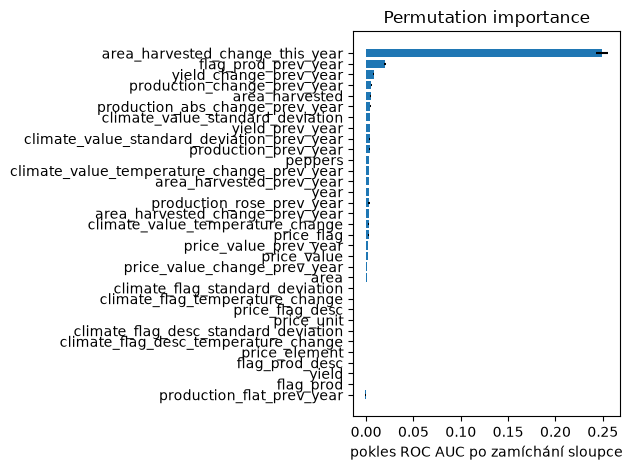

In [9]:
# ===== adapted from: scripts/train_production_clf.py  (part 7/8: permutation importance) =====
r = permutation_importance(
    pipeline, X_train, y_train,
    scoring="roc_auc", n_repeats=20, random_state=42, n_jobs=-1,
)

importance = (pd.DataFrame({
    "feature": X_train.columns,
    "mean": r.importances_mean,
    "std": r.importances_std,
}).sort_values("mean"))

plt.barh(importance["feature"], importance["mean"], xerr=importance["std"])
plt.xlabel("pokles ROC AUC po zamíchání sloupce")
plt.title("Permutation importance")
plt.tight_layout(); plt.show()

In [10]:
Výsledná pipeline (předzpracování + model dohromady) se uloží do `models/production_clf.pkl`, odkud ji načítá nástroj `predict_production_rise` (část C).

SyntaxError: invalid syntax (1602424916.py, line 1)

In [ ]:
# ===== copied verbatim from: scripts/train_production_clf.py  (part 8/8: save model) =====
joblib.dump(pipeline, PRODUCTION_MODEL_PATH)

['models\\production_clf.pkl']

# Část B — Obrazový model: klasifikátor odrůd chilli

## B.1 Data
Fotografie **13 odrůd chilli** v `data/training/varieties/{train,valid,test}/<class>/`. Třídy: Besar Hijau, Besar Merah, Domba, Gendot, Habanero, Italiano, Jalapeno, Keriting Hijau, Keriting Merah, Paprika, Rawit Hijau, Rawit Merah, Tanjung. Název složky je zároveň popiskem, takže `torchvision.datasets.ImageFolder` čte popisky přímo.

## B.2 Model
- **ResNet18** předtrénovaný na ImageNetu, jehož poslední plně propojená vrstva je nahrazena hlavou pro 13 tříd.
- Obrázky se normalizují průměrem/směrodatnou odchylkou ImageNetu, které předtrénované váhy očekávají.
  Při trénování se používá augmentace (`RandomResizedCrop(224)`, `RandomHorizontalFlip`). Testovací obrázky procházejí `Resize(224)` + `CenterCrop(224)`.
- **Optimalizátor** Adam s `lr = 1e-4`. Malá rychlost učení zabraňuje přepsání předtrénovaných příznaků. **Ztrátová funkce:** křížová entropie. **Velikost dávky:** 32.
- Checkpoint ukládá váhy, stav optimalizátoru, názvy tříd a přesnost. Pokud není k dispozici lokálně, stáhne se z Hugging Face.
- Nástroj `classify_plant_type` (část C) vrací **3 nejpravděpodobnější odrůdy s jejich pravděpodobnostmi** (softmax).

In [19]:
# ===== adapted from: tools/variety_model.py (třída variety_model přepsána na sekvenční kód) =====
from pathlib import Path
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms, datasets, models
from huggingface_hub import hf_hub_download

PATH_VARIETY_MODEL = Path("models/varieties/checkpoint.pt")
PATH_TRAINING_DATA = Path("data/training/varieties/train")
PATH_VALIDATION_DATA = Path("data/training/varieties/valid")
PATH_TESTING_DATA = Path("data/training/varieties/test")
HF_MODEL_REPO_ID = "DanSvobodaVSE/chillbot-varieties"

TRAIN = False  # Set to True if you want to train the model from scratch

# Průměr a směrodatná odchylka kanálů R, G, B z datasetu ImageNet, na kterém je ResNet18 předtrénovaný.
# Obrázky se normalizují stejně jako při předtrénování: (pixel - mean) / std.
TF_MEAN = [0.485, 0.456, 0.406]
TF_STD = [0.229, 0.224, 0.225]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=TF_MEAN, std=TF_STD)
])

test_tf = transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=TF_MEAN, std=TF_STD)
])

# Checkpoint obsahuje vahy, stav optimalizatoru i nazvy trid; kdyz lokalne chybi, stahne se z Hugging Face
if not PATH_VARIETY_MODEL.exists() and not TRAIN:
    print(f"No trained model found at {PATH_VARIETY_MODEL}. Downloading from Hugging Face...")
    hf_hub_download(
        repo_id=HF_MODEL_REPO_ID,
        filename=PATH_VARIETY_MODEL.name,
        local_dir=str(PATH_VARIETY_MODEL.parent),
    )
    
checkpoint = torch.load(PATH_VARIETY_MODEL, map_location=device)
if TRAIN:
    # Datasety: nazev slozky = popisek tridy
    train_dataset = datasets.ImageFolder(root=PATH_TRAINING_DATA, transform=train_tf)
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    valid_dataset = datasets.ImageFolder(root=PATH_VALIDATION_DATA, transform=test_tf)
    valid_loader = DataLoader(valid_dataset, batch_size=32, shuffle=False)
    test_dataset = datasets.ImageFolder(root=PATH_TESTING_DATA, transform=test_tf)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
    classes = train_dataset.classes
    print(f"Number of training samples: {len(train_dataset)}")
    print(f"Number of classes: {len(classes)}")

    # ResNet18 s hlavou pro nase tridy; vahy se hned nactou z checkpointu
    variety_net = models.resnet18(weights=None)
    variety_net.fc = nn.Linear(variety_net.fc.in_features, len(classes))
    variety_net.load_state_dict(checkpoint["model"])
    variety_net = variety_net.to(device)

    optimizer = torch.optim.Adam(variety_net.parameters(), lr=1e-4)
    if "optimizer" in checkpoint and TRAIN:
        optimizer.load_state_dict(checkpoint["optimizer"])
    criterion = nn.CrossEntropyLoss()
    print(f"Prepared for training")

Using device: cpu


## B.3 Trénování
Trénování je navrženo až po **10 epoch**. Po každé epoše se model vyhodnotil na testovací množině a uložil, nakonec se checkpoint nahrál na Hugging Face.
Funkce `train()`, `evaluate()` a `save_model()` ze skriptu jsou zde rozepsány přímo do smyčky přes epochy. Trénování je vypnuté přepínačem `TRAIN = False`, aby spuštění notebooku model znovu netrénovalo a nepřepsalo checkpoint. Pro nové natrénování stačí nastavit `TRAIN = True`.

In [25]:
# ===== adapted from: scripts/train_varieties.py (funkce train, evaluate a save_model přepsány na sekvenční kód) =====
from huggingface_hub import HfApi

MODEL_PATH = PATH_VARIETY_MODEL
EPOCHS = 10
valid_loss_arr = [0.0956, 0.0423, 0.2508, 0.0847, 0.1535, 0.0973, 0.0611, 0.1312, 0.1804, 0.1873]
train_loss_arr = [0.1881, 0.1985, 0.2138, 0.2001, 0.2267, 0.2954, 0.2094, 0.3284, 0.2538, 0.3349]
accuracy_arr = [0.9630, 0.9943, 0.4074, 0.9715, 0.9430, 0.9630, 0.9744, 0.9658, 0.9288, 0.9316]

if TRAIN:
    valid_loss_arr = []
    train_loss_arr = []
    accuracy_arr = []
    best_valid_loss = float("inf")
    for epoch in range(EPOCHS):
        # trenovani jedne epochy
        variety_net.train()
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = variety_net(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)
        train_loss = running_loss / len(train_loader.dataset)

        # vyhodnoceni na validacni mnozine
        variety_net.eval()
        correct = 0
        valid_loss = 0.0
        with torch.no_grad():
            for inputs, labels in valid_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = variety_net(inputs)
                valid_loss += criterion(outputs, labels).item() * inputs.size(0)
                correct += torch.sum(outputs.argmax(dim=1) == labels)
        
        valid_loss /= len(valid_loader.dataset)

        accuracy = correct.double() / len(valid_loader.dataset)
        valid_loss_arr.append(valid_loss)
        train_loss_arr.append(train_loss)
        accuracy_arr.append(accuracy)
        print(f"Epoch [{epoch + 1}/{EPOCHS}], Train Loss: {train_loss:.4f}, Valid Loss: {valid_loss:.4f}, Accuracy: {accuracy:.2%}")
        if valid_loss < best_valid_loss:
            best_valid_loss = valid_loss
            print(f"New best valid loss: {valid_loss:.4f}")
            print("Validation loss decreased, saving model...")
            torch.save({
                "epoch": epoch,
                "model": variety_net.state_dict(),
                "optimizer": optimizer.state_dict(),
                "classes": classes,
                "accuracy": accuracy,
            }, MODEL_PATH)
            print(f"Model saved to {MODEL_PATH}")

    api = HfApi()
    try:
        api.create_repo(HF_MODEL_REPO_ID, repo_type="model", exist_ok=True)
        api.upload_file(
            path_or_fileobj=MODEL_PATH,
            path_in_repo="checkpoint.pt",
            repo_id=HF_MODEL_REPO_ID,
        )
    except:
        print("Uploading model failed, use uploaded model instead")

**Vyhodnocení:** zobrazení trénovacích epoch a vývoj trénování

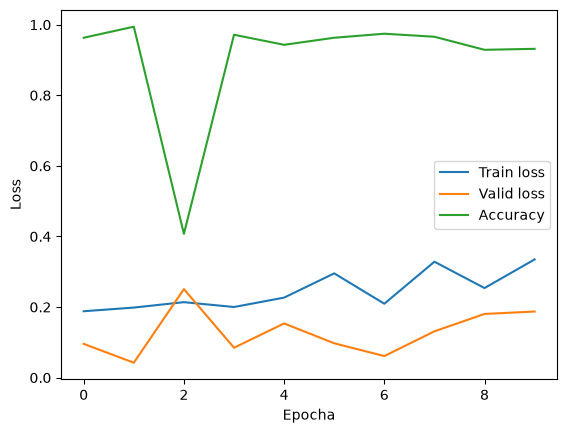

In [26]:

plt.plot(train_loss_arr, label="Train loss")
plt.plot(valid_loss_arr, label="Valid loss")
plt.plot(accuracy_arr, label="Accuracy")
plt.xlabel("Epocha")
plt.ylabel("Loss")
plt.legend()
plt.show()




# Část C — Zpřístupnění modelů jako tools (nástrojů) pro LLM

Oba modely jsou obyčejné Python funkce.

LLM nástroje volá přes **function calling** v OpenAI-kompatibilním API: aplikace mu pošle jejich popis (`tools=`, viz D.2), LLM odpoví požadavkem na volání a aplikace funkci spustí sama (D.3). Nejsou potřeba žádné další servery ani porty.

## C.1 Nástroj predikce produkce
Vstupy nástroje popisuje pydantic třída `ProductionInput`. Z ní se přes `model_json_schema()` vygeneruje JSON Schema `PRODUCTION_PARAMETERS`, které dostane LLM, a stejná třída při volání zkontroluje, že argumenty od LLM mají správné typy. **Povinné** je jen to, co uživatel může reálně dodat: země, typ papriky, rok, letošní a loňská plocha a loňská produkce. Všechny ostatní příznaky jsou volitelné. Pokud některý chybí, doplní ho mediánový imputer v pipeline.

In [27]:
# ===== adapted from: tools/production.py =====
import math
from pathlib import Path

import joblib
import pandas as pd
from pydantic import BaseModel, Field

MODEL_PATH = Path("models/production_clf.pkl")

production_model = joblib.load(MODEL_PATH)

CATEGORICAL = {
    "area",
    "peppers",
    "climate_flag_standard_deviation",
    "climate_flag_temperature_change",
    "price_flag",
    "flag_prod_prev_year",
}


class ProductionInput(BaseModel):
    # povinne: kde, co, kdy, plocha letos vs. loni a loňská produkce
    area: str = Field(description="Country name as in FAOSTAT, e.g. 'Spain'")
    peppers: str = Field(description="'fresh' or 'dry'")
    year: int
    area_harvested: float = Field(description="Area harvested (planted) this year, ha")
    area_harvested_prev_year: float = Field(description="Area harvested last year, ha")
    production_prev_year: float = Field(description="Production last year, t")
    # volitelne
    yield_prev_year: float | None = None
    price_value: float | None = None
    price_value_prev_year: float | None = None
    climate_value_standard_deviation: float | None = None
    climate_value_temperature_change: float | None = None
    climate_value_standard_deviation_prev_year: float | None = None
    climate_value_temperature_change_prev_year: float | None = None
    production_change_prev_year: float | None = Field(None, description="log(production t-1 / production t-2)")
    yield_change_prev_year: float | None = None
    area_harvested_change_prev_year: float | None = None
    price_value_change_prev_year: float | None = None
    climate_flag_standard_deviation: str | None = None
    climate_flag_temperature_change: str | None = None
    price_flag: str | None = None
    flag_prod_prev_year: str | None = None


# Vstupni schema pro LLM (JSON Schema) se generuje z pydantic tridy
PRODUCTION_PARAMETERS = ProductionInput.model_json_schema()


def predict_production_rise(**args):
    """Predicts whether pepper production in a country rises vs. last year, given this year's harvested area."""
    # pydantic zkontroluje typy a povinna pole; pri chybe vyhodi ValidationError (podtrida ValueError)
    input_data = ProductionInput(**args)
    features = input_data.model_dump()
    features["area_harvested_change_this_year"] = (
        math.log(input_data.area_harvested / input_data.area_harvested_prev_year)
        if input_data.area_harvested > 0 and input_data.area_harvested_prev_year > 0
        else None
    )
    change = input_data.production_change_prev_year
    features["production_flat_prev_year"] = None if change is None else float(change == 0)
    features["production_rose_prev_year"] = None if change is None else float(change > 0)
    features["production_abs_change_prev_year"] = None if change is None else abs(change)

    # None -> NaN (float) u ciselnych, object u kategorickych, jinak imputer/encoder spadne
    X = pd.DataFrame([features])
    X = X.astype({c: object if c in CATEGORICAL else float for c in X.columns})
    proba = float(production_model.predict_proba(X)[0, 1])
    return {"production_rise": int(proba >= 0.5), "probability": round(proba, 3)}

## C.2 Nástroj klasifikace odrůd
Síť je načtená už v části B (`variety_net`), nástroj jen připraví obrázek stejnou transformací jako testovací data a vrátí 3 nejpravděpodobnější odrůdy (v repozitáři metoda `variety_model.predict()`). Nástroj dostává **cestu k fotografii** relativně ke kořeni projektu, protože argumenty nástrojů jsou JSON od LLM a fotografie leží u aplikace.

In [ ]:
# ===== adapted from: tools/variety.py (metoda variety_model.predict vložena přímo do nástroje) =====
from pathlib import Path

from PIL import Image

# variety_net, test_tf, classes a device jsou z části B


def classify_plant_type(image_path: str) -> str:
    """
    Identifies the chilli variety in a photo.

    Args:
        image_path: Path to the photo (JPEG or PNG), relative to the project root.

    Returns:
        The top 3 most likely chilli varieties with their probabilities.
    """
    image = Image.open(Path(image_path)).convert("RGB")

    variety_net.eval()
    with torch.inference_mode():
        x = test_tf(image).unsqueeze(0).to(device)   # [3,224,224] -> [1,3,224,224]
        probs = torch.softmax(variety_net(x), dim=1)[0]
    top = torch.topk(probs, 3)

    lines = [f"- {classes[i]}: {p:.1%}" for p, i in zip(top.values.tolist(), top.indices.tolist())]
    return "Most likely chilli varieties:\n" + "\n".join(lines)

**Ukázka:** klasifikace jedné fotografie z testovací množiny.

In [ ]:
# ----- NOTEBOOK GLUE (not part of the repository code) -----
_img_path = sorted(Path("data/training/varieties/test").rglob("*.jp*g"))[0]
print("skutečná třída:", _img_path.parent.name)
print(classify_plant_type(str(_img_path)))

# Část D — Chatbot

## D.1 Znalostní báze pro RAG
- Znalostní bázi tvoří PDF dokumenty v `data/knowledge/` (`papriky.pdf`).
- Text se extrahuje po stránkách (`pypdf`) a `RecursiveCharacterTextSplitter` ho dělí na **chunky o 1000 znacích s překryvem 200 znaků** (`RAG_CHUNK_SIZE`, `RAG_CHUNK_OVERLAP`).
- Chunky se ukládají do **ChromaDB** (`data/vector_store/`) s výchozím embeddingem Chromy. Index se sestaví jednou, když je kolekce prázdná.
- Při dotazu se vyhledá **5 nejpodobnějších** chunků (`RAG_TOP_K`).

In [ ]:
# ===== adapted from: web/rag.py (třída DocumentDB přepsána na sekvenční kód) =====
from datetime import datetime, timezone
from pathlib import Path

import chromadb
from langchain_text_splitters import RecursiveCharacterTextSplitter
from pypdf import PdfReader

KNOWLEDGE_DIR = Path("data/knowledge")
VECTOR_STORE_DIR = Path("data/vector_store")
COLLECTION_NAME = "chilli_collection"
CHUNK_SIZE = 1000
CHUNK_OVERLAP = 200
RETRIEVAL_COUNT = 5

chroma_client = chromadb.PersistentClient(path=str(VECTOR_STORE_DIR))
collection = chroma_client.get_or_create_collection(COLLECTION_NAME)

# Index se sestavi jen jednou, kdyz je kolekce prazdna
if collection.count() == 0:
    if not KNOWLEDGE_DIR.is_dir():
        raise FileNotFoundError(
            f"Knowledge directory does not exist: {KNOWLEDGE_DIR}"
        )

    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size=CHUNK_SIZE,
        chunk_overlap=CHUNK_OVERLAP,
    )

    pdf_files = sorted(KNOWLEDGE_DIR.rglob("*.pdf"))
    if not pdf_files:
        raise FileNotFoundError(
            f"No PDF files found in knowledge directory: {KNOWLEDGE_DIR}"
        )

    indexed_at = datetime.now(timezone.utc).isoformat()

    for pdf_path in pdf_files:
        reader = PdfReader(str(pdf_path))
        relative_source = pdf_path.relative_to(KNOWLEDGE_DIR).as_posix()

        for page_number, page in enumerate(reader.pages, start=1):
            page_text = " ".join((page.extract_text() or "").split())
            chunks = text_splitter.split_text(page_text)

            for chunk_index, chunk in enumerate(chunks):
                chunk_id = (
                    f"{relative_source}:{page_number}:"
                    f"{chunk_index}:{indexed_at}"
                )
                collection.upsert(
                    documents=[chunk],
                    metadatas=[{
                        "source": relative_source,
                        "page": page_number,
                        "chunk": chunk_index,
                        "indexed_at": indexed_at,
                    }],
                    ids=[chunk_id],
                )

print("Chunků v kolekci:", collection.count())

**Ukázka:** vyhledání pro vzorovou otázku (v repozitáři metoda `DocumentDB.get_documents()`). Chroma vrací seznam výsledků pro každý dotaz, proto se čte `[0]`.

In [ ]:
# ----- NOTEBOOK GLUE (not part of the repository code) -----
_hits = collection.query(query_texts=["Jak pěstovat chilli papričky?"], n_results=RETRIEVAL_COUNT)["documents"][0]
for i, chunk in enumerate(_hits, 1):
    print(f"{i}. {chunk[:200]}…\n")

## D.2 Registr Tools
`TOOLS` popisuje oba nástroje ve formátu *function calling* (`chat.completions`, parametr `tools=`). `TOOL_FUNCTIONS` přiřazuje jménu nástroje, které pošle LLM, jeho funkci. Argumenty přijdou od LLM jako JSON řetězec a výsledek se vrací jako text pro zprávu s rolí `tool`.

In [ ]:
# ===== adapted from: tools/registry.py (funkce run_tool rozepsána přímo do ukázky a do smyčky chatu v D.3) =====
import json

# PRODUCTION_PARAMETERS, predict_production_rise a classify_plant_type jsou definovány v části C

# Popisy nastroju ve formatu function calling (chat.completions, parametr tools=)
TOOLS = [
    {
        "type": "function",
        "function": {
            "name": "predict_production_rise",
            "description": (
                "Predicts whether chilli/pepper production in a country rises vs. last year, "
                "given this year's harvested area and last year's production."
            ),
            "parameters": PRODUCTION_PARAMETERS,
        },
    },
    {
        "type": "function",
        "function": {
            "name": "classify_plant_type",
            "description": "Identifies the chilli variety in a photo and returns the top 3 varieties.",
            "parameters": {
                "type": "object",
                "properties": {
                    "image_path": {
                        "type": "string",
                        "description": "Path to the photo (JPEG or PNG), relative to the project root.",
                    },
                },
                "required": ["image_path"],
            },
        },
    },
]

# Jmeno nastroje, ktere posle LLM -> funkce nastroje
TOOL_FUNCTIONS = {
    "predict_production_rise": predict_production_rise,
    "classify_plant_type": classify_plant_type,
}

**Ukázka:** nástroje se zavolají stejně, jako by o ně požádalo LLM: jméno nástroje a argumenty jako JSON řetězec. Poslední volání ukazuje chybu vrácenou jako text.

In [ ]:
# ----- NOTEBOOK GLUE (not part of the repository code) -----
print([t["function"]["name"] for t in TOOLS])

_tool_calls = [
    ("predict_production_rise", json.dumps({
        "area": "Spain", "peppers": "fresh", "year": 2023,
        "area_harvested": float(_row["area_harvested"]),
        "area_harvested_prev_year": float(_row["area_harvested_prev_year"]),
        "production_prev_year": float(_row["production_prev_year"]),
    })),
    ("classify_plant_type", json.dumps({"image_path": str(_img_path)})),
    ("classify_plant_type", json.dumps({"image_path": "neexistuje.jpg"})),
]
for name, arguments in _tool_calls:
    try:
        result = TOOL_FUNCTIONS[name](**json.loads(arguments))
    except (KeyError, json.JSONDecodeError, TypeError, OSError, ValueError) as error:
        result = f"Error while running {name}: {error}"
    print(f"{name} -> {result}")

## D.3 LLM s Tools (nástroji)
### 👉 Vyzkoušejte sami
V buňce níže **vyplňte svůj API klíč** pro endpoint `litellm.vse.cz` a případně **změňte otázku**. Pak spusťte tuto a další buňky. Pokud klíč zůstane prázdný, volání LLM se přeskočí a notebook i tak doběhne do konce (*Run All*).

V buňce je slovník `QUESTIONS` s testovacími otázkami. Otázku vyberete přes `QUESTION = QUESTIONS["..."]`, nebo nastavte `RUN_ALL = True` a projedou se všechny. Otázky testují:
- **nástroj produkce**: běžný dotaz, sušené papriky, volitelný údaj navíc, chybějící údaje (LLM se má doptat, ne vymýšlet) a anglický dotaz s jiným názvem země
- **nástroj odrůd**: dvě existující fotky a jednu neexistující (LLM má ohlásit chybu)
- **znalostní báze (RAG)**: otázky na pěstování bez nástrojů
- **kombinace a hranice**: dva nástroje v jedné otázce a otázku mimo téma (žádný nástroj)

In [ ]:
API_KEY = ""   # např. "sk-..."; klíč nesdílejte a před odevzdáním/commitem ho smažte

QUESTIONS = {
    "produkce": (
        "Vzroste v roce 2023 produkce čerstvých paprik ve Španělsku, když se sklízelo "
        "na 20 000 ha oproti loňským 19 000 ha a loni se vyprodukovalo 1 500 000 t?"
    ),
    "produkce_sušené": (
        "Indie v roce 2022 sklidila sušené chilli z 678 000 ha, rok předtím z 702 000 ha, "
        "a loni vyprodukovala 2 049 000 t. Vzroste produkce?"
    ),
    "produkce_volitelné": (
        "Mexiko 2022, čerstvé papriky: sklizeň na 156 932 ha (loni 147 808 ha), loňská produkce "
        "2 584 144 t a index cen výrobců 132,8. Vzroste produkce?"
    ),
    "produkce_chybí_údaje": "Vzroste letos produkce paprik v Česku?",
    "produkce_anglicky": (
        "Will fresh pepper production in the Czech Republic rise in 2021? Harvested area was 310 ha "
        "this year and 290 ha last year, last year's production was 12 230 t."
    ),

    "odrůda": "Jaká odrůda chilli je na fotce data/training/varieties/test/Jalapeno/jalapenoNew_32_Jalapeno_Bilateral.jpg?",
    "odrůda_habanero": "Co je to za papričku? data/training/varieties/test/Harbanero/162_Median - Copy - Copy.jpg",
    "odrůda_neexistuje": "Jaká odrůda je na fotce data/fotky/moje_paprika.jpg?",

    "rag_pěstování": "Jak pěstovat chilli papričky?",
    "rag_podmínky": "Jakou teplotu, světlo a zálivku potřebují papriky, aby dobře rostly?",

    "dva_nástroje": (
        "Na fotce data/training/varieties/test/Rawit Merah/17_RawitMerah_Bilateral.jpg je moje paprička, co je to za odrůdu? "
        "A ještě: vzroste v roce 2023 produkce čerstvých paprik ve Španělsku, když se sklízelo "
        "na 20 000 ha oproti loňským 19 000 ha a loni se vyprodukovalo 1 500 000 t?"
    ),
    "mimo_téma": "Jaké bude zítra počasí v Praze?",
}

QUESTION = QUESTIONS["produkce"]   # vyberte otázku podle klíče
RUN_ALL = False   # True = projede postupně všechny otázky (trvá déle a spotřebuje víc tokenů)

In [ ]:
# ===== adapted from: web/app.py (/api/chat bez Flasku a bez streamování; create_stream, stream_with_tools a run_tool přepsány na sekvenční kód) =====
from datetime import datetime as dt
from openai import OpenAI, OpenAIError

LLM_BASE_URL = "https://litellm.vse.cz/v1/"
LLM_MODEL = "qwen3.6-35b"

# Kolikrat po sobe muze LLM volat nastroje, nez musi odpovedet textem
MAX_TOOL_ROUNDS = 5

if not API_KEY:
    print("API_KEY není vyplněný, volání LLM se přeskočí. Doplňte klíč v buňce 👉 výše a spusťte znovu.")
else:
    llm_client = OpenAI(base_url=LLM_BASE_URL, api_key=API_KEY)
    questions = QUESTIONS if RUN_ALL else {"vybraná": QUESTION}
    for question_name, QUESTION in questions.items():
        print(f"\n===== {question_name}: {QUESTION}")
        messages = [{"role": "user", "content": QUESTION}]

        # 1. RAG: relevantni chunky ze znalostni baze jako referencni material
        known_documents = collection.query(query_texts=[QUESTION], n_results=RETRIEVAL_COUNT)["documents"][0]
        messages.append({
            "role": "assistant",
            "content": (
                "Here are the relevant documents from the knowledge base. "
                "Use them as reference material:\n\n"
                + "\n\n".join(known_documents)
            ),
        })

        try:
            # o jedno kolo vic: posledni dotaz je bez nastroju a LLM musi odpovedet textem
            for tool_round in range(MAX_TOOL_ROUNDS + 1):
                # 2. LLM dostane konverzaci a nastroje
                response = llm_client.chat.completions.create(
                    model=LLM_MODEL,
                    messages=messages,
                    tools=TOOLS,
                    tool_choice="auto" if tool_round < MAX_TOOL_ROUNDS else "none",
                )
                message = response.choices[0].message

                # 4. odpoved textem bez volani nastroju = konec
                if not message.tool_calls:
                    print(message.content)
                    break

                # 3. spustit pozadovane nastroje a vysledky pridat do konverzace
                messages.append(message.model_dump(exclude_none=True))
                for call in message.tool_calls:
                    name = call.function.name
                    arguments = call.function.arguments
                    print(f"Running tool {name}({arguments}) {dt.now()}")
                    try:
                        result = TOOL_FUNCTIONS[name](**json.loads(arguments or "{}"))
                        result = result if isinstance(result, str) else json.dumps(result)
                    except (KeyError, json.JSONDecodeError, TypeError, OSError, ValueError) as error:
                        # chybu vratime LLM, aby mohl opravit argumenty misto padu celeho chatu
                        result = f"Error while running {name}: {error}"
                    print("  ->", result)
                    messages.append({"role": "tool", "tool_call_id": call.id, "content": result})
        except OpenAIError as error:
            print("LLM endpoint vrátil chybu, zkontrolujte API klíč:", error)

💡 **Možná vylepšení chatbota**
- **Chyba v repozitáři:** `DocumentDB.get_documents()` vrací `results["documents"]`, což je *seznam seznamů* (jeden seznam na dotaz). `"\n\n".join(known_documents)` v `/api/chat` (`web/app.py`) proto vyhodí `TypeError` a každý požadavek na chat s nastaveným klíčem skončí HTTP 500. Stejně selže i ukázka v `__main__` v `rag.py` (`result.strip()`). Notebook čte rovnou `[0]`. V repozitáři to opraví vracení `results["documents"][0]`.
- Vyhledaný kontext se vkládá jako zpráva s rolí `assistant`. Obvyklé je použít zprávu `system` (nebo zprávu, která říká, že jde o vyhledaný kontext), aby ho model nepovažoval za něco, co sám řekl.
- Webové rozhraní ve Flasku zatím neumí nahrát fotografii a API klíč v něm je globální pro celý server (všichni uživatelé sdílejí naposledy zadaný klíč).
- Soubory v `tests/` a `scripts/index_knowledge.py` jsou prázdné.

# Revize notebooku: nalezené chyby

## 1. Chyby, kvůli kterým notebook nedoběhne (*Run All*)

| # | Kde | Problém | Důsledek | Oprava |
|---|---|---|---|---|
| 1.1 | B.2 (načtení modelu) | Datasety, `classes`, `variety_net`, `optimizer` a `criterion` se vytvoří jen uvnitř `if TRAIN:`. | Při výchozím `TRAIN = False` spadne na `NameError` vyhodnocení na testu, ukázka v C.2, ukázka v D.2 a chat v D.3, pokud LLM zavolá `classify_plant_type` (`NameError` není v `except`). | Datasety a načtení modelu dát mimo `if TRAIN:`. Větvit jen podle toho, odkud se vezmou váhy: checkpoint, nebo ImageNet. |
| 1.2 | D.2 (ukázka nástrojů) | Používá `_row`, který se definoval ve smazané ukázkové buňce za C.1. | `NameError`. | Vrátit definici `_row`, nebo v ukázce použít pevná čísla. |

## 2. Chyba v datech (A.2)

**Pivot podle příznaků zahazuje zhruba 16 % dat.**
- `peppers.pivot(index=["flag_prod", "flag_prod_desc", ..., "year"], ...)` má příznak v indexu.
- Když má produkce jiný příznak než plocha (např. produkce `A`, plocha `E`), rozdělí se jeden rok na dva neúplné řádky a `dropna(how="any")` oba smaže.
- V datech to platí pro **1 747 z 10 926** kombinací země–rok. Následující rok pak nemá `production_prev_year` a vypadne také.
- Ztrácejí se hlavně odhadnuté hodnoty, takže to data i zkresluje.
- **Oprava:** pivotovat jen podle `area, peppers, year` a příznak produkce připojit zvlášť.

## 3. Logické chyby

- **B.3: `TRAIN = True` netrénuje znovu.** Síť se načte z checkpointu i se stavem optimizeru, takže se jen dotrénovává. Pro nové trénování začít z `ResNet18_Weights.DEFAULT`.
- **B.3: ukládá se poslední epocha, ne nejlepší.** Checkpoint se přepisuje po každé epoše. Ukládat jen při zlepšení validační přesnosti.
- **B.3: automatický upload na Hugging Face.** Po natrénování se bez ptaní přepíše veřejný model. Dát upload za samostatný přepínač.
- **B.3: `accuracy` se ukládá jako tensor.** Ukládat `accuracy.item()`.
- **C.1: nástroj nepozná špatný vstup.** `peppers: str` přijme cokoliv. Hodnotu `"čerstvé"`, `"green"` nebo neznámý název země one-hot encoder (`handle_unknown="ignore"`) tiše ignoruje a předpověď vyjde bez této informace. Použít `Literal["fresh", "dry"]` a zkontrolovat zemi proti zemím z trénovacích dat.
- **A.2: cenový filtr nic nedělá.** U indexu cen výrobců mají všechny řádky (5 277) příznak „Estimated value“. Filtr na „Time series break“ / „Value from external organization“ tak použitá data neovlivní, ať je s `|` nebo s `&`.

## 4. Texty, které neodpovídají kódu

| Kde | Text | Skutečnost |
|---|---|---|
| A.2 (po kódu) | „znovu vygenerovaný soubor je shodný s tím v repozitáři“ | Po změnách neověřeno. |
| A.3, tabulka „Volba modelu“ | výsledky modelů | Ze staršího běhu, ověřit novým spuštěním. |
| A.3, „Vybrané modely“ | čtyři odrážky | Odrážky jsou prázdné. |
| B.1 | třída „Habanero“ | Složka i název třídy je „Harbanero“. |
| B.3 | „vyhodnotil na testovací množině“ | Kód používá validační množinu (`valid_loader`). |
| Vylepšení obrazového modelu | „Množina `valid/` se nikde nepoužívá“ | Používá se v B.3. |
| Buňka s balíčky | seznam balíčků | Chybí `pydantic`, který potřebuje C.1. |
| A.3, „Výběr nejlepšího modelu“ | „použijem“, „Na konci ještě na testovacích datech, vypisuji…“ | Překlepy. |

## 5. Drobnosti

- **Permutační důležitost** se počítá pro všechny sloupce `X_train`, i ty, které model nepoužívá (`flag_prod_desc`, `price_unit`, letošní `yield`…). V grafu mají nulu. Počítá se na trénovacích datech, na testovacích by byla vypovídající.
- **RAG index** se staví jen nad prázdnou kolekcí. Po změně PDF se nepřestaví, dokud se nesmaže `data/vector_store/`.
- **D.3:** vyhledaný kontext se posílá jako zpráva `assistant`, obvyklejší je `system`.
- **Repozitář:** `web/rag.py` pořád vrací `results["documents"]` (seznam seznamů). `tests/*` a `scripts/index_knowledge.py` jsou prázdné.

## Doporučené pořadí oprav
1. Body 1.1 a 1.2, aby notebook doběhl.
2. Bod 2 (pivot), protože mění data, na kterých se model učí. Pak znovu spustit A.2 a A.3 a aktualizovat tabulku.
3. Logické chyby v B.3 a C.1.
4. Texty z bodu 4.